In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

In [2]:
def minmax_normalize(img):
    return cv2.normalize(img, None, 0, 1, cv2.NORM_MINMAX,dtype=cv2.CV_32F)


def fft(image):
    image_fft = np.fft.fft2(image)
    fft_shift = np.fft.fftshift(image_fft)
    image_magnitude = np.abs(fft_shift)
    image_phase = np.angle(fft_shift)

    return fft_shift, image_magnitude, image_phase

def inverse_fft(image):
    return np.abs(np.fft.ifft2(np.fft.ifftshift(image)))


# Question 1

In [3]:
def percentile_contrast_stretching(image, p_low=1, p_high=99):
    low_val = np.percentile(image, p_low)
    high_val = np.percentile(image, p_high)
    
    print(f"Stretching range: {low_val} to {high_val}")
    
    output = np.clip(image, low_val, high_val)
    
    output = ((output - low_val) / (high_val - low_val)) * 255
    
    return output.astype(np.uint8)

Original Image Min: 41, Original Image Max: 255
Stretching range: 56.0 to 123.0


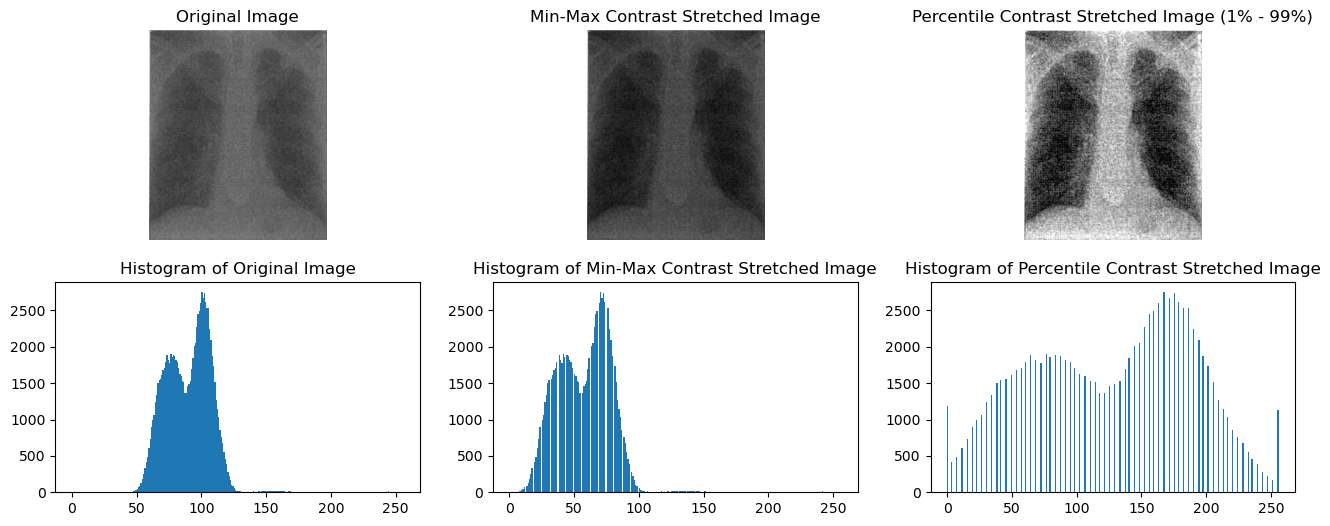

In [4]:
image1 = cv2.imread('./imgs/x-ray.PNG', cv2.IMREAD_GRAYSCALE)
print(f'Original Image Min: {image1.min()}, Original Image Max: {image1.max()}')

image1_minmax_contrast_stretch = minmax_normalize(image1) * 255
image1_percentile_contrast_stretch = percentile_contrast_stretching(image1)

plt.figure(figsize=(16,6))

plt.subplot(2,3,1)
plt.title('Original Image')
plt.axis('off')
plt.imshow(image1, cmap='gray', vmin=0)

plt.subplot(2,3,4)
plt.title('Histogram of Original Image')
plt.hist(image1.ravel(), 256, [0, 256])

plt.subplot(2,3,2)
plt.title('Min-Max Contrast Stretched Image')
plt.axis('off')
plt.imshow(image1_minmax_contrast_stretch, cmap='gray', vmin=0)

plt.subplot(2,3,5)
plt.title('Histogram of Min-Max Contrast Stretched Image')
plt.hist(image1_minmax_contrast_stretch.ravel(), 256, [0, 256])

plt.subplot(2,3,3)
plt.title('Percentile Contrast Stretched Image (1% - 99%)')
plt.axis('off')
plt.imshow(image1_percentile_contrast_stretch, cmap='gray', vmin=0)

plt.subplot(2,3,6)
plt.title('Histogram of Percentile Contrast Stretched Image')
plt.hist(image1_percentile_contrast_stretch.ravel(), 256, [0, 256]);

# Question 2

Text(0.5, 1.0, 'Histogram Equalization')

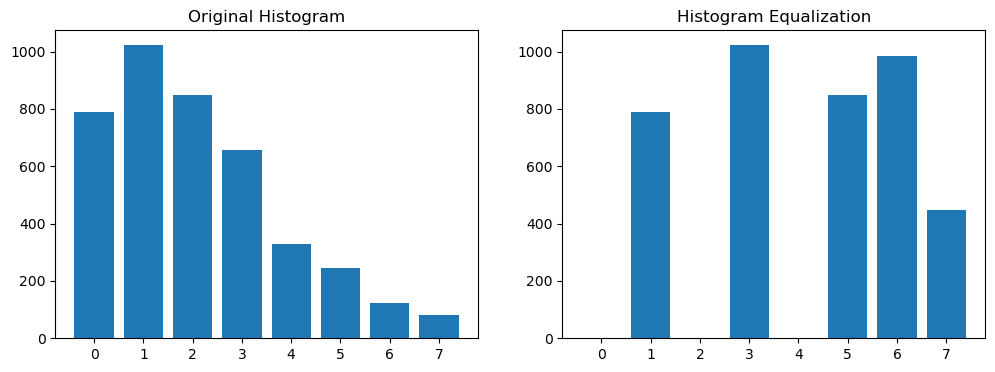

In [5]:
intensities = np.array([0, 1, 2, 3, 4, 5, 6, 7])
counts = np.array([790, 1023, 850, 656, 329, 245, 122, 81])
counts2 = np.array([0, 790, 0, 1023, 0, 850, 656+329, 245+122+81 ])

plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
plt.bar(intensities, counts)
plt.title('Original Histogram')

plt.subplot(1,2,2)
plt.bar(intensities, counts2)
plt.title('Histogram Equalization')

# Question 3

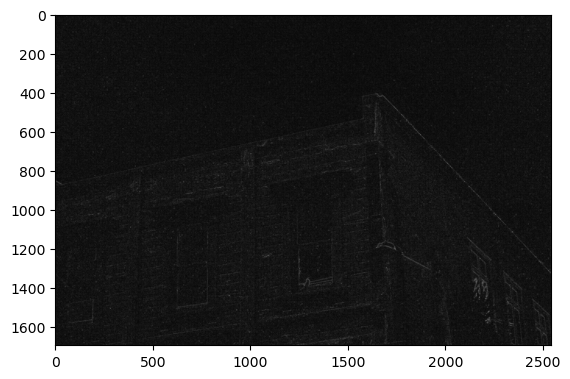

In [7]:
image3 = cv2.imread('./imgs/building.jpg', cv2.IMREAD_GRAYSCALE)
image3_fft, image3_magnitude, image3_phase = fft(image3)

image3_phase_only = inverse_fft(1 * np.exp(1j * image3_phase))
plt.imshow(image3_phase_only, cmap='gray');

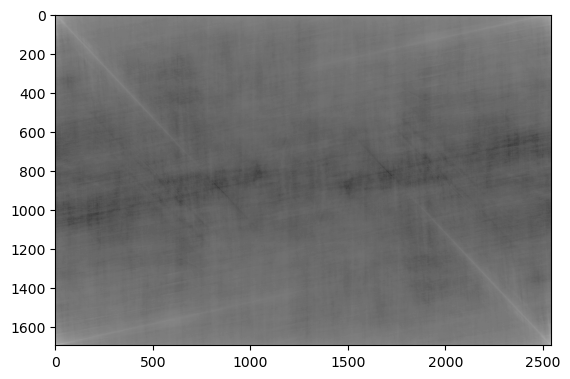

In [8]:
image3_no_phase = inverse_fft(image3_magnitude * np.exp(1j * 0))
plt.imshow(np.log1p(image3_no_phase), cmap='gray');

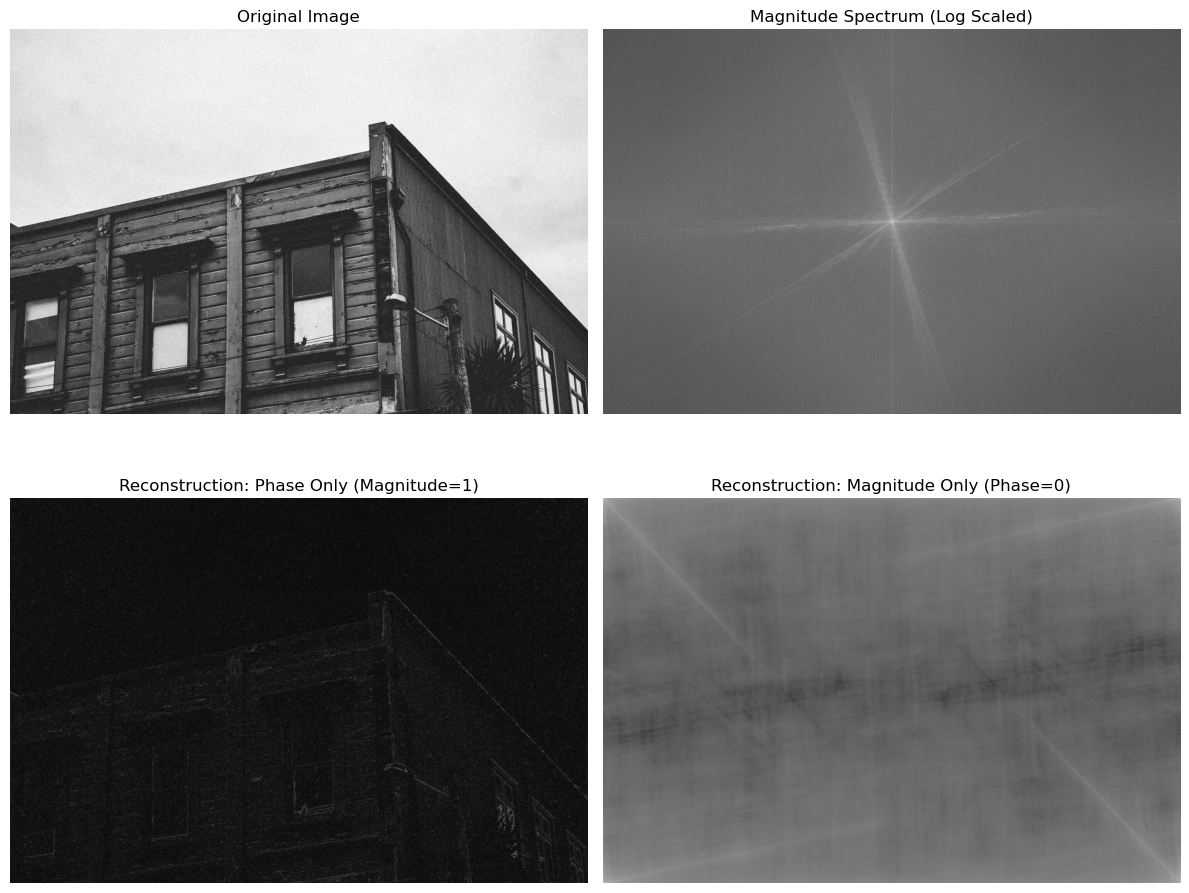

In [9]:
plt.figure(figsize=(12, 10))

plt.subplot(2, 2, 1)
plt.imshow(image3, cmap='gray')
plt.title("Original Image")
plt.axis('off')

plt.subplot(2, 2, 2)
plt.imshow(np.log1p(image3_magnitude), cmap='gray')
plt.title("Magnitude Spectrum (Log Scaled)")
plt.axis('off')

plt.subplot(2, 2, 3)
plt.imshow(image3_phase_only, cmap='gray')
plt.title("Reconstruction: Phase Only (Magnitude=1)")
plt.axis('off')

plt.subplot(2, 2, 4)
plt.imshow(np.log1p(image3_no_phase), cmap='gray')
plt.title("Reconstruction: Magnitude Only (Phase=0)")
plt.axis('off')

plt.tight_layout()
plt.show()

# Question 4

In [10]:
def gaussian_filter(image, sigma=1, kernel_size=7):
    gaussian_kernel = np.zeros((kernel_size, kernel_size))

    for i in range(kernel_size):
        for j in range(kernel_size):
            x = i - kernel_size // 2
            y = j - kernel_size // 2
            gaussian_kernel[i, j] = (1 / (2 * np.pi * sigma**2)) * np.exp(-(x**2 + y**2) / (2 * sigma**2))
            
    return cv2.filter2D(image, -1, gaussian_kernel)

def sobel_gradients(image):
    kx = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]])
    ky = np.array([[1, 2, 1], [0, 0, 0], [-1, -2, -1]])

    Ix = cv2.filter2D(image, cv2.CV_32F, kx)
    Iy = cv2.filter2D(image, cv2.CV_32F, ky)

    magnitude = np.sqrt(Ix ** 2 + Iy ** 2)
    magnitude = magnitude / magnitude.max() * 255
    theta = np.arctan2(Iy, Ix) # Gradient Direction (radians)
    return magnitude, theta

def non_max_suppression(magnitude, theta):
    final = np.zeros_like(magnitude)
    angle = theta * 180 / np.pi #radian to degree
    angle[angle < 0] += 180 #the degrees will be in range (0,180)

    for i in range(1, magnitude.shape[0] - 1):
        for j in range(1, magnitude.shape[1] - 1):
            if (0 <= angle[i, j] < 22.5) or (157.5 <= angle[i, j] <= 180):
                a = magnitude[i, j+1]
                b = magnitude[i, j-1]

            elif (22.5 <= angle[i, j] < 67.5):
                a = magnitude[i+1, j-1]
                b = magnitude[i-1, j+1]
            
            elif (67.5 <= angle[i, j] < 112.5):
                a = magnitude[i+1, j]
                b = magnitude[i-1, j]

            elif (112.5 <= angle[i, j] < 157.5):
                a = magnitude[i-1, j-1]
                b = magnitude[i+1, j+1]

            if (magnitude[i, j] >= b) and (magnitude[i, j] >= a):
                final[i, j] = magnitude[i, j]
                
    return final

def canny1_3(image):
    image = gaussian_filter(image)
    magnitude, theta = sobel_gradients(image)
    return non_max_suppression(magnitude, theta)


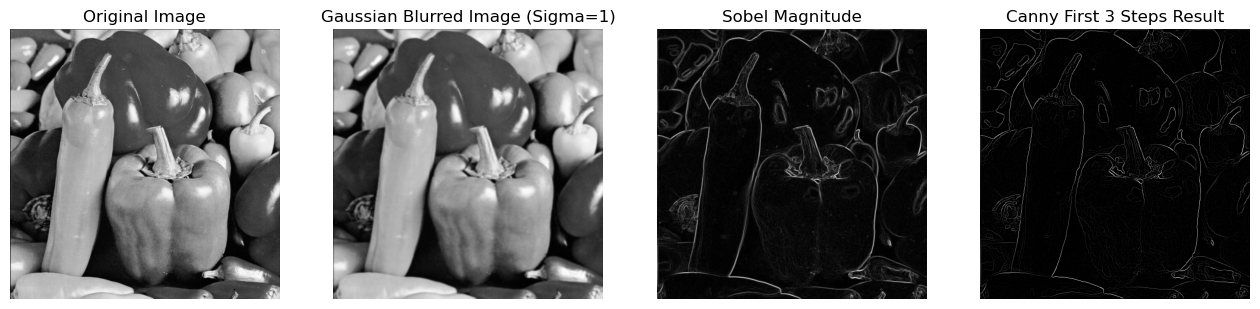

In [11]:
image4 = cv2.imread('./imgs/pepper.jpg', cv2.IMREAD_GRAYSCALE)
image4_canny = canny1_3(image4)

plt.figure(figsize=(16,18))

plt.subplot(1,4,1)
plt.title('Original Image')
plt.axis('off')
plt.imshow(image4, cmap='gray')

plt.subplot(1,4,2)
plt.title('Gaussian Blurred Image (Sigma=1)')
plt.axis('off')
plt.imshow(gaussian_filter(image4, sigma=1), cmap='gray')

plt.subplot(1,4,3)
plt.title('Sobel Magnitude')
plt.axis('off')
plt.imshow(sobel_gradients(image4)[0], cmap='gray')

plt.subplot(1,4,4)
plt.title('Canny First 3 Steps Result')
plt.axis('off')
plt.imshow(image4_canny, cmap='gray');

# Question 5

In [12]:
image5 = cv2.imread('./imgs/pepper.jpg', 0)
#image5 = cv2.resize(image5, (512, 512)) 
image5 = minmax_normalize(image5)
layer = image5.copy()
    
# Create Gaussian Pyramid
gaussian_pyramid = [layer]
levels = 3
for i in range(levels):
    img_blur = cv2.GaussianBlur(layer, (7,7), 1)
    layer = cv2.pyrDown(layer)
    gaussian_pyramid.append(layer)


# Create Laplacian Pyramid
laplacian_pyramid = [gaussian_pyramid[levels]]
for i in range(levels, 0, -1):
    #upsampled = cv2.resize(gaussian_pyramid[i], None, fx=2, fy=2, interpolation=cv2.INTER_LINEAR)
    upsampled = cv2.pyrUp(gaussian_pyramid[i])
    diff = gaussian_pyramid[i-1] - upsampled
    laplacian_pyramid.append(diff)

# Reconstruct
reconstruct = [laplacian_pyramid[0]]
for i in range(levels):
    reconstructed = cv2.pyrUp(reconstruct[i]) + laplacian_pyramid[i+1]
    reconstruct.append(reconstructed)

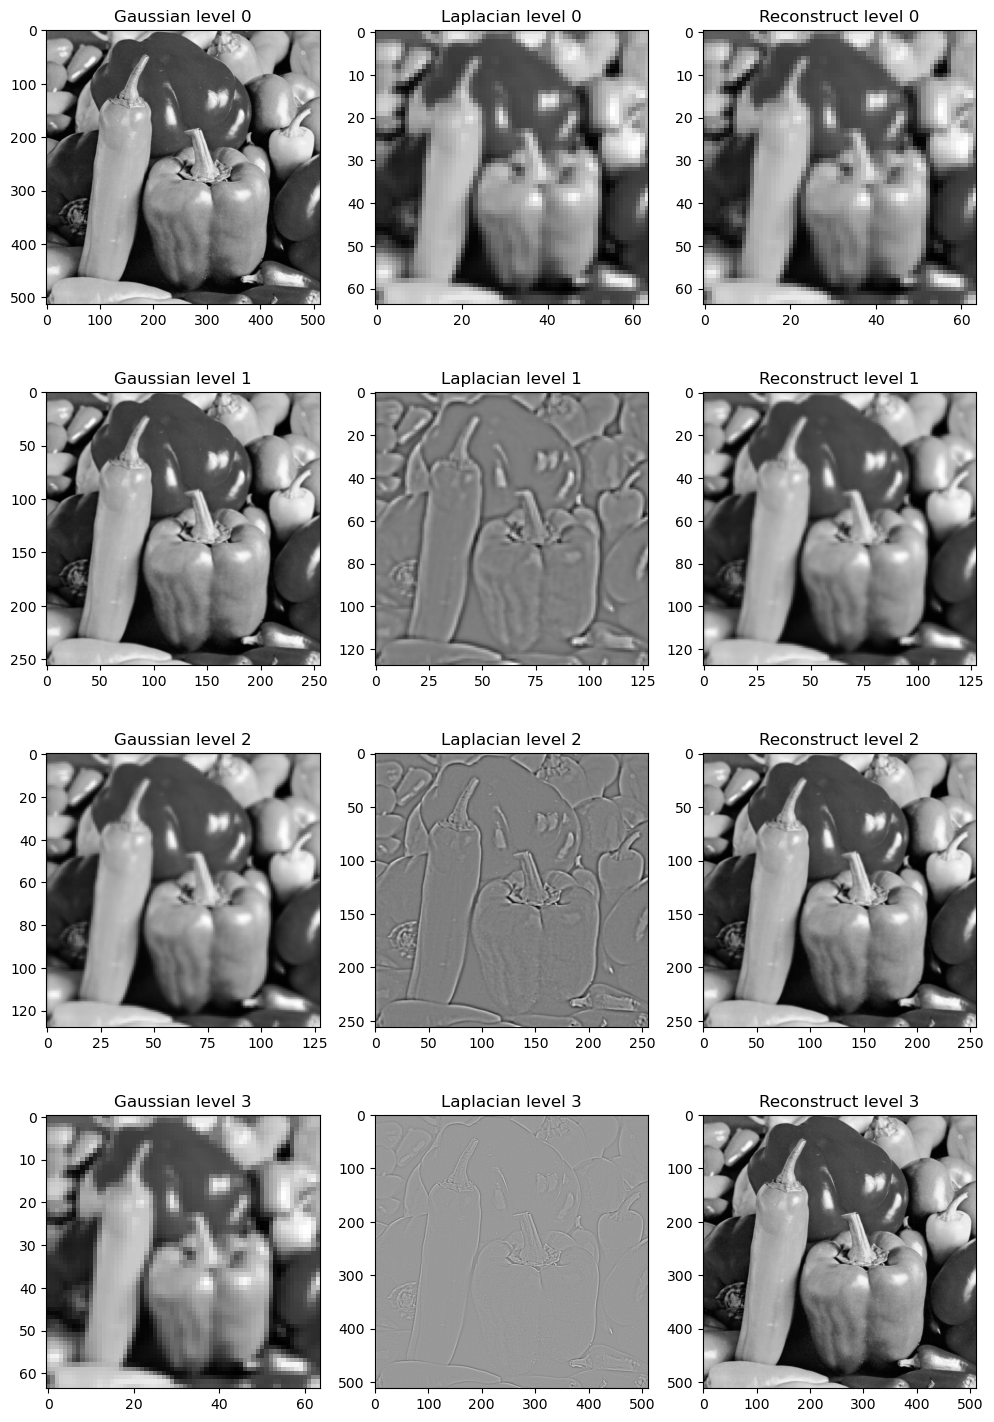

In [13]:
num_levels = levels + 1

plt.figure(figsize=(12, 18))

for i in range(num_levels):

    plt.subplot(num_levels, 3, 3*i + 1)
    plt.imshow(gaussian_pyramid[i], cmap='gray')
    plt.title(f'Gaussian level {i}')

    plt.subplot(num_levels, 3, 3*i + 2)
    plt.imshow(laplacian_pyramid[i], cmap='gray')
    plt.title(f'Laplacian level {i}')

    plt.subplot(num_levels, 3, 3*i + 3)
    plt.imshow(reconstruct[i], cmap='gray')
    plt.title(f'Reconstruct level {i}')


# Question 6

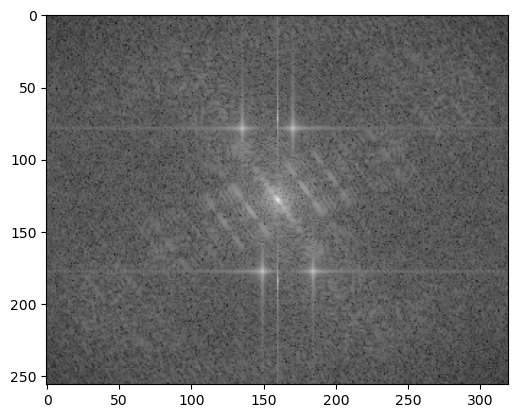

In [14]:
image6 = cv2.imread('./imgs/noiseball.png', cv2.IMREAD_GRAYSCALE)

fft_shift, image6_magnitude, _ = fft(image6)

plt.imshow(np.log1p(image6_magnitude), cmap='gray');

50
25


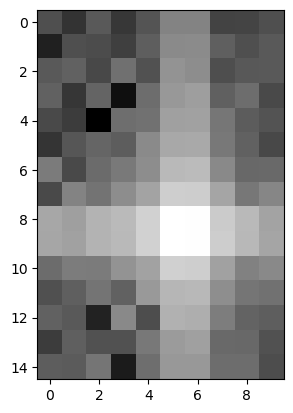

In [15]:
plt.imshow(np.log1p(image6_magnitude[70:85, 130:140]), cmap='gray') #the location of bright dots are near (78,135)
#calculate distance to the center of image
print(image6.shape[0]//2 - 78)
print(image6.shape[1]//2 - 135)

50
-10


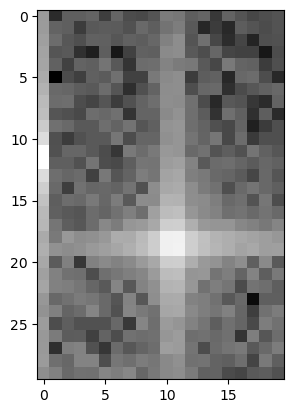

In [16]:
plt.imshow(np.log1p(image6_magnitude[60:90, 160:180]), cmap='gray') #the location of bright dots are near (78,170)
#calculate distance to the center of image
print(image6.shape[0]//2 - 78)
print(image6.shape[1]//2 - 170)

In [17]:
def butterworth_mask(shape, cutoff_freq, order):
    mask = np.zeros(shape, np.float32)
    x, y = shape
    for i in range(x):
        for j in range(y):
            mask[i,j]= (1 / (1 + (np.linalg.norm([i - (x // 2), j - (y // 2)], ord=2)/cutoff_freq)**(2 * order)))
    return 1 - mask

def notch_filter(distance_to_center, radius, image):
    mask = np.ones_like(image)

    points = [(image.shape[1]//2 - distance_to_center[1], image.shape[0]//2 - distance_to_center[0]), (image.shape[1]//2 + distance_to_center[1], image.shape[0]//2 + distance_to_center[0])]
    
    cv2.circle(mask, points[0], radius, 0 , -1)
    cv2.circle(mask, points[1], radius, 0 , -1)
    
    return mask

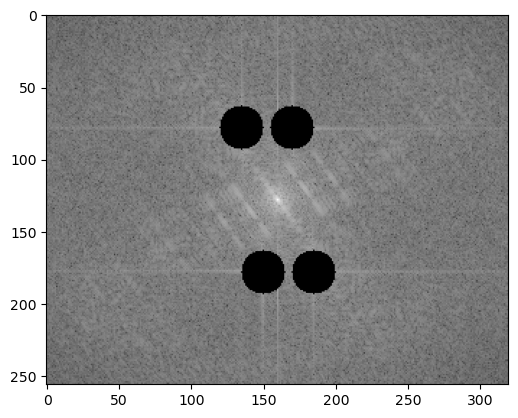

In [18]:
radius = 15
first_notch = notch_filter([50,25], radius, image6)
second_notch = notch_filter([50, -10], radius, image6)

filtered_image_freq = fft_shift * first_notch * second_notch
# filtered_image_freq[:120, 160] = 0
# filtered_image_freq[135:, 160] = 0

plt.imshow(np.abs(np.log1p(filtered_image_freq)), cmap='gray');

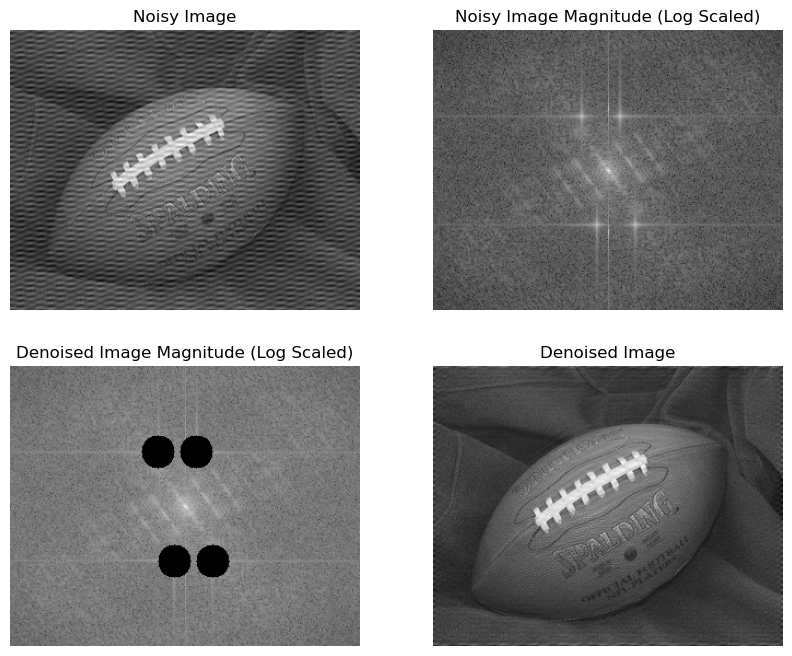

In [19]:
filtered_image_spatial = inverse_fft(filtered_image_freq)
final_image = minmax_normalize(filtered_image_spatial)

plt.figure(figsize=(10,8))

plt.subplot(2,2,1)
plt.title('Noisy Image')
plt.axis('off')
plt.imshow(image6, cmap='gray')

plt.subplot(2,2,2)
plt.title('Noisy Image Magnitude (Log Scaled)')
plt.axis('off')
plt.imshow(np.abs(np.log1p(image6_magnitude)), cmap='gray')

plt.subplot(2,2,3)
plt.title('Denoised Image Magnitude (Log Scaled)')
plt.axis('off')
plt.imshow(np.abs(np.log1p(filtered_image_freq)), cmap='gray')

plt.subplot(2,2,4)
plt.title('Denoised Image')
plt.axis('off')
plt.imshow(final_image, cmap='gray');